---
title: "Week 8 Homework"
subtitle: "DS 2023 | Communicating with Data"
---

## Overview

In this assignment we use Pandas and Matplotlib to explore every birth in the United States from 2000 to 2014. 

We practice two complementary skills covered in Unit 6: adding **annotations** that guide the reader's eye to what matters, and composing **subplots** that show the same data through different lenses at once.

## The dataset

The `births` dataset was published by FiveThirtyEight, using counts from the Social Security Administration.

It records the number of babies born in the United States on each day from January 1, 2000 to December 31, 2014. Each row is one day.

| Column | Description |
|---|---|
| `year` | Year (2000–2014) |
| `month` | Month (1–12) |
| `date_of_month` | Day of the month (1–31) |
| `day_of_week` | Day of the week: 1 = Monday, …, 7 = Sunday |
| `births` | Number of births that day |

In Task 0 we add four columns:

| Column | Description |
|---|---|
| `date` | The full date |
| `day_name` | `'Mon'`, `'Tue'`, …, `'Sun'` |
| `month_name` | `'Jan'`, `'Feb'`, …, `'Dec'` |
| `day_type` | `'Weekday'` or `'Weekend'` |

## Tasks

Each task (except 0) is worth 2 points. 

Fractions will be given for partial credit.

## Task 0

Set load and transform the data.

Add `date`, `day_name`, `month_name` and `day_type` columns. 

Make `day_name` and `month_name` ordered categories, so that days and months sort in calendar order rather than alphabetically.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
BIRTHS = pd.read_csv('https://datahub.io/fivethirtyeight/births/_r/-/data/US_births_2000-2014_SSA.csv')
BIRTHS.head()

,year,month,date_of_month,day_of_week,births
0,2000,1,1,6,9083
1,2000,1,2,7,8006
2,2000,1,3,1,11363
3,2000,1,4,2,13032
4,2000,1,5,3,12558


We create a true date column using `pd.to_datetime()`.

Since `pd.to_datetime()` builds dates from columns
named `year`, `month` and `day`, we rename
`date_of_month` first.

In [9]:
BIRTHS = BIRTHS.rename(columns={'date_of_month':'day'})
BIRTHS['date'] = pd.to_datetime(BIRTHS[['year', 'month', 'day']])
BIRTHS.head()

,year,month,day,day_of_week,births,date
0,2000,1,1,6,9083,2000-01-01
1,2000,1,2,7,8006,2000-01-02
2,2000,1,3,1,11363,2000-01-03
3,2000,1,4,2,13032,2000-01-04
4,2000,1,5,3,12558,2000-01-05


Next, we extract some useful grouping variables form the date.

In [10]:
import calendar as cal

# Convert name lists to dicts for using in map
days = {i+1:day for i, day in enumerate(cal.day_abbr[:])}
months = {i+1:month for i, month in enumerate(cal.month_abbr[1:])} # For some reason the first element is blank

# Map and the names to numbers and convert to categories
BIRTHS['day_name'] = BIRTHS.day_of_week.map(days)
BIRTHS['day_name'] = pd.Categorical(BIRTHS['day_name'], categories=cal.day_abbr[:], ordered=True)
BIRTHS['month_name'] = BIRTHS.month.map(months)
BIRTHS['month_name'] = pd.Categorical(BIRTHS['month_name'], categories=cal.month_abbr[1:], ordered=True)

# Create two new groups
BIRTHS['day_type'] = np.where(BIRTHS['day_of_week'] >= 6, 'Weekend', 'Weekday')
BIRTHS.head()

,year,month,day,day_of_week,births,date,day_name,month_name,day_type
0,2000,1,1,6,9083,2000-01-01,Sat,Jan,Weekend
1,2000,1,2,7,8006,2000-01-02,Sun,Jan,Weekend
2,2000,1,3,1,11363,2000-01-03,Mon,Jan,Weekday
3,2000,1,4,2,13032,2000-01-04,Tue,Jan,Weekday
4,2000,1,5,3,12558,2000-01-05,Wed,Jan,Weekday


## Task 1

**Reference line on a histogram**

Plot a histogram of `births` with 30 bins.

Add a vertical reference line at the **mean** number of births with `ax.axvline()`.

Label the line near the top using `ax.text()` with `ax.get_xaxis_transform()`, showing the mean value with a thousands separator and no decimals.

Show the text annotation on the left side of the line and make sure there is some space between the text and the line.

**Question.**

Describe the shape of the distribution. Where does the mean fall, and is it a good summary of a typical day?

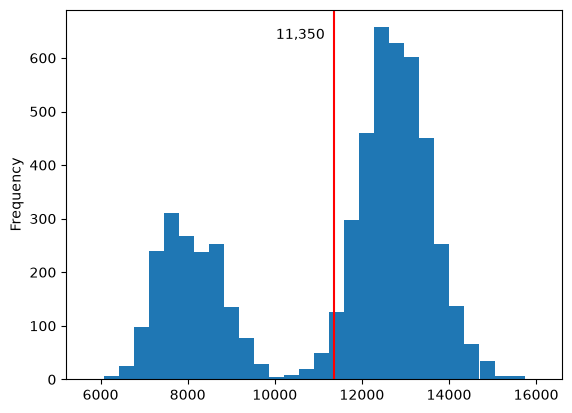

In [22]:
ax = BIRTHS.births.plot.hist(bins=30)
mean_births = BIRTHS["births"].mean()
ax.axvline(mean_births, color="red")
ax.text(
    mean_births - 200,
    0.95,
    f"{mean_births:,.0f}",
    transform=ax.get_xaxis_transform(),
    ha="right",
    va="top"
)
plt.show()

Question 1:

The distrubution is bimodal. The mean falls at a lower value of the second hump, and is probably a decent summary of a typical day, however it is much lower than many of the possible values. Since the first hump is so much smaller than the second hump, the mean is skewed slightly low.

## Task 2

**Bar labels**

Compute the mean `births` for each `day_name`.

Plot the result as a horizontal bar chart with Monday at the top.

Use `ax.bar_label()` with `fmt='{:,.0f}'` to print each mean on its bar.

Remove x and y labels and give the plot the title "Mean births per day".

**Question.**

Which day of the week has the most births on average, and which has the fewest?

[Text(2, 0, '7,518'),
 Text(2, 0, '8,563'),
 Text(2, 0, '12,596'),
 Text(2, 0, '12,846'),
 Text(2, 0, '12,911'),
 Text(2, 0, '13,122'),
 Text(2, 0, '11,898')]

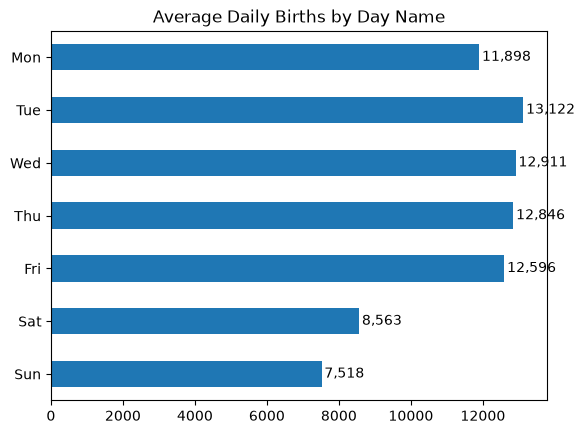

In [28]:
mean_by_day = BIRTHS.groupby("day_name")["births"].mean()
ax = mean_by_day.iloc[::-1].plot.barh()
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Average Daily Births by Day Name")
ax.bar_label(ax.containers[0], fmt='{:,.0f}', padding = 2)

Question:

Sunday has the fewest mean births, while Tuesday has the highest mean births.

## Task 3

**Annotating an extreme**

Create a scatter plot of `date` (x-axis) vs `births` (y-axis). 

Color the points light gray and make them small (`s=3`).

Find the day with the most births using `idxmax()`. 

Select that row as a one-row data frame with `BIRTHS.loc[[peak_idx]]` and draw it in red with `.plot.scatter()` on the same axes. 

Use `ax.annotate()` to add a callout label. 

The label should show the date in textual form, e.g. "January 10, 2005", and the number of births. 

Place the text in a legible area to the lower right of the point, using `textcoords='offset points'` as your way to place the text.

Be sure to remove the top and right spines so that text and point don't overlap the spines.

Give the plot the title "Births per day".

**Question.**

On which day were the most babies born, and how many? Can you guess why that day?

Text(0.5, 1.0, 'Births per day')

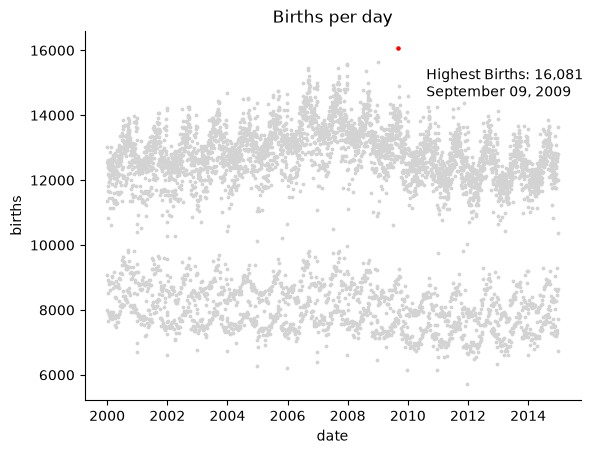

In [46]:
ax = BIRTHS.plot.scatter("date", "births", color = "lightgray", s=3)
most_births = BIRTHS["births"].idxmax()
ax.scatter(
    BIRTHS.loc[most_births, "date"],
    BIRTHS.loc[most_births, "births"],
    color="red",
    s=5
)
peak_date = BIRTHS.loc[most_births, "date"]
peak_value = BIRTHS.loc[most_births, "births"]
ax.annotate(
    f"Highest Births: {peak_value:,}\n{peak_date:%B %d, %Y}",
    xy=(peak_date, peak_value),
    xytext=(20, -35),
    textcoords="offset points"
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_title("Births per day")

Question:

On September 9th, 2009, 16081 babies were born. This might be because conception rates tend to be higher during the winter holidays, leading to September birthdays.

## Task 4

**Direct labeling**

Pivot the data to compute the mean `births` grouped by `year` and `day_type`.

Plot the result as two lines (one per day type) with `legend=False`.

Loop through `ax.lines` to add a direct label at the **last** data point of each line. 

Give each label the same color as its line.

Remove the top and right spines to give the labels more space.

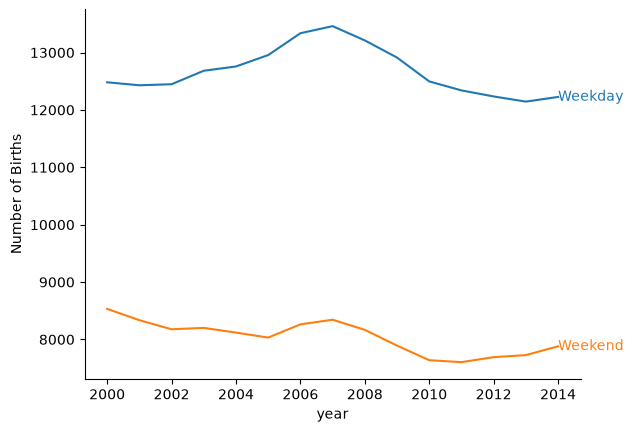

In [57]:
births_by_year = BIRTHS.pivot_table(
    index="year",
    columns="day_type",
    values="births",
    aggfunc="mean"
)
ax = births_by_year.plot(y=['Weekday', 'Weekend'], legend=False)
ax.set_ylabel("Number of Births")
for line in ax.lines:
    x = line.get_xdata()[-1]
    y = line.get_ydata()[-1]

    ax.text(x, y, line.get_label(), color=line.get_color(), va="center")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

**Question.**

From 2000 to 2014, which day type saw the larger drop in births, in percent?

Weekend saw the larger drop in births, since it started as a much lower number and dropped roughly the same amount as Weekday.

## Task 5

**Mosaic with a spanning panel**

Use `plt.subplot_mosaic('AA;BC', layout='constrained')` to create a figure.

- In panel `A` put a scatter plot of `date` vs `births` with `plot.scatter()` (light gray points, `s=3`, `alpha=0.4`).
- In panel `B` put a histogram of `births` (20 bins).
- In panel `C` put a bar chart of total `births` per `year`.

Set axis labels on each panel and add a figure title with `fig.suptitle()`.

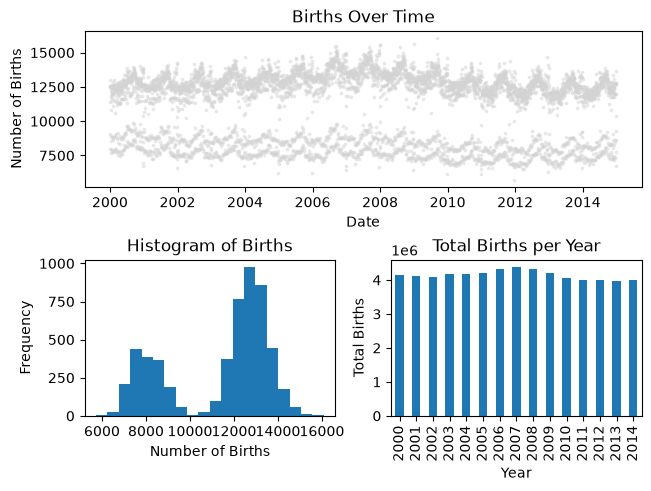

In [62]:
fig, ax = plt.subplot_mosaic('AA;BC', layout='constrained')

BIRTHS.plot.scatter(
    x='date',
    y='births',
    ax=ax['A'],
    color='lightgray',
    s=3,
    alpha=0.4
)

BIRTHS['births'].plot.hist(
    bins=20,
    ax=ax['B']
)

BIRTHS.groupby('year')['births'].sum().plot.bar(
    ax=ax['C']
)
ax['A'].set_title('Births Over Time')
ax['B'].set_title('Histogram of Births')
ax['C'].set_title('Total Births per Year')

ax['A'].set_xlabel('Date')
ax['A'].set_ylabel('Number of Births')
ax['B'].set_xlabel('Number of Births')
ax['C'].set_xlabel('Year')
ax['C'].set_ylabel('Total Births')
plt.show()